# Sugar Cosmetics Instagram Analytics: Data Preprocessing

**Deliverable 1 of 3.** This notebook validates the raw Instagram export, engineers the fields the Streamlit dashboard needs, runs the statistical checks that decide how the dashboard should talk about the data, and exports one clean file.

**What this notebook produces**

| Output | Used by |
|---|---|
| `dashboard/data/sugar_ig_clean.csv` | every dashboard page |
| `dashboard/data/analysis_summary.json` | the Findings page (model check, partial months, thresholds) |
| `dashboard/data/data_dictionary.csv` | README and handover |

**Order of work:** load, validate, clean, engineer features, check signal vs noise, export.

## 1. Setup

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

# Palette shared with the dashboard
ROUGE, APRICOT, NUDE, BERRY, ORCHID, TEAL = "#FF3D6E", "#FF9E6D", "#F2C9B8", "#B5487F", "#8E7CC3", "#4FC3B5"
plt.rcParams.update({
    "figure.facecolor": "#130F14", "axes.facecolor": "#1C1720", "axes.edgecolor": "#3A2F40",
    "axes.labelcolor": "#F5EEF0", "xtick.color": "#A99DAE", "ytick.color": "#A99DAE",
    "text.color": "#F5EEF0", "axes.grid": True, "grid.color": "#2A2330", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})

# The notebook looks for the raw file in a few likely places so it runs from any folder.
CANDIDATES = [
    Path("../data/raw/sugar_cosmetics_instagram_data.xlsx"),
    Path("data/raw/sugar_cosmetics_instagram_data.xlsx"),
    Path("sugar_cosmetics_instagram_data.xlsx"),
]
RAW_PATH = next(p for p in CANDIDATES if p.exists())
OUT_DIR = Path("../dashboard/data") if Path("../dashboard").exists() else Path("dashboard/data")
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Raw file :", RAW_PATH.resolve())
print("Output   :", OUT_DIR.resolve())

Raw file : /home/claude/sugar_ig_analytics/data/raw/sugar_cosmetics_instagram_data.xlsx
Output   : /home/claude/sugar_ig_analytics/dashboard/data


## 2. Load and first look

In [2]:
raw = pd.read_excel(RAW_PATH, sheet_name=0)
print(f"Rows: {len(raw):,}   Columns: {raw.shape[1]}")
raw.head()

Rows: 50,000   Columns: 14


,Post Date,Post Type,Campaign Type,Hashtags,Audience Emotion,Engagement Source,Impressions,Reach,Likes,Comments,Shares,Saves,Profile Visits,Follows
0,2024-12-23,Story,Giveaway,"#SugarCosmetics, #MakeupGoals, #BoldLooks",Curious,Collab,16795,15665,3076,430,73,99,193,86
1,2024-06-01,Image,Tutorial,"#BoldLooks, #MakeupGoals, #VeganBeauty",Confident,Influencer,45131,29335,5285,308,396,502,294,146
2,2024-04-28,Reel,Festive Offer,#VeganBeauty,Confident,Collab,18568,13118,2032,233,73,140,204,44
3,2025-02-01,Reel,Product Launch,"#CrueltyFree, #VeganBeauty, #SugarCosmetics",Happy,Collab,1189,751,130,13,12,7,33,12
4,2024-08-04,Story,Tutorial,"#SugarCosmetics, #VeganBeauty",Curious,Organic,15502,9373,2234,300,99,47,180,35


In [3]:
raw.dtypes.to_frame("dtype").join(raw.nunique().rename("unique")).join(raw.isna().sum().rename("nulls"))

,dtype,unique,nulls
Post Date,datetime64[us],366,0
Post Type,str,4,0
Campaign Type,str,5,0
Hashtags,str,85,0
Audience Emotion,str,5,0
Engagement Source,str,4,0
Impressions,int64,31462,0
Reach,int64,29010,0
Likes,int64,8604,0
Comments,int64,1677,0


## 3. Validation

Nothing is changed in this section. The goal is to find out what the data needs, not to fix things by habit. Every check below is a rule that a real Instagram export should satisfy.

In [4]:
df = raw.copy()
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))
print(list(df.columns))

checks = {
    "Duplicate rows": int(df.duplicated().sum()),
    "Null cells": int(df.isna().sum().sum()),
    "Reach greater than impressions": int((df.reach > df.impressions).sum()),
    "Likes + comments + shares + saves greater than reach": int(((df.likes + df.comments + df.shares + df.saves) > df.reach).sum()),
    "Follows greater than profile visits": int((df.follows > df.profile_visits).sum()),
    "Negative numeric values": int((df.select_dtypes("number") < 0).sum().sum()),
    "Zero reach or impressions": int(((df.reach == 0) | (df.impressions == 0)).sum()),
    "Leading or trailing spaces in text": int(sum((df[c] != df[c].str.strip()).sum() for c in df.select_dtypes(["object", "string"]).columns)),
}
pd.Series(checks, name="rows failing").to_frame()

['post_date', 'post_type', 'campaign_type', 'hashtags', 'audience_emotion', 'engagement_source', 'impressions', 'reach', 'likes', 'comments', 'shares', 'saves', 'profile_visits', 'follows']


,rows failing
Duplicate rows,0
Null cells,0
Reach greater than impressions,0
Likes + comments + shares + saves greater than reach,0
Follows greater than profile visits,0
Negative numeric values,0
Zero reach or impressions,0
Leading or trailing spaces in text,0


In [5]:
for col in ["post_type", "campaign_type", "audience_emotion", "engagement_source"]:
    print(f"{col:18s}", df[col].value_counts().to_dict())

all_tags = df.hashtags.str.split(", ").explode()
print()
print("Distinct hashtags:", all_tags.nunique(), all_tags.value_counts().to_dict())
print("Hashtags per post:", df.hashtags.str.split(", ").str.len().value_counts().sort_index().to_dict())
print("Date range       :", df.post_date.min().date(), "to", df.post_date.max().date(), f"({df.post_date.nunique()} distinct dates)")

post_type          {'Reel': 12599, 'Story': 12517, 'Video': 12485, 'Image': 12399}
campaign_type      {'Tutorial': 10186, 'Giveaway': 9998, 'Festive Offer': 9990, 'Product Launch': 9923, 'Influencer Collab': 9903}
audience_emotion   {'Inspired': 10137, 'Excited': 10061, 'Curious': 10027, 'Confident': 9891, 'Happy': 9884}
engagement_source  {'Collab': 12633, 'Organic': 12508, 'Influencer': 12501, 'Paid': 12358}



Distinct hashtags: 5 {'#CrueltyFree': 20197, '#MakeupGoals': 20018, '#VeganBeauty': 19982, '#BoldLooks': 19956, '#SugarCosmetics': 19891}
Hashtags per post: {1: 16625, 2: 16706, 3: 16669}
Date range       : 2024-04-19 to 2025-04-19 (366 distinct dates)


**What validation tells us**

- The file is already clean: no nulls, no duplicates, no logical contradictions. Preprocessing here is feature engineering and documentation, not repair.
- There is no caption column, no post ID, no posting time and no follower count, even though the project brief lists a caption. The dashboard builds a readable post label from format, campaign and date instead.
- Hashtags are stored as a text list drawn from only five tags, with one to three per post. They are stored in inconsistent order, so the same combination can appear as different strings. That needs normalising.
- The first and last months are partial. Any monthly volume chart that ignores this will show a false ramp up and a false drop.

## 4. Cleaning

In [6]:
df["post_date"] = pd.to_datetime(df["post_date"]).dt.normalize()

text_cols = ["post_type", "campaign_type", "audience_emotion", "engagement_source", "hashtags"]
for c in text_cols:
    df[c] = df[c].astype(str).str.strip()

# Keep the original row position so every post can be traced back to the raw file.
df.insert(0, "source_row", np.arange(2, len(df) + 2))   # Excel row number (header is row 1)
df.insert(0, "post_id", ["SC" + str(i).zfill(5) for i in range(1, len(df) + 1)])

int_cols = ["impressions", "reach", "likes", "comments", "shares", "saves", "profile_visits", "follows"]
df[int_cols] = df[int_cols].astype("int64")
df.shape

(50000, 16)

## 5. Feature engineering

### 5.1 Engagement rate definition

The project brief asks for an average engagement rate but does not define it. This analysis uses

> **Engagement rate = (likes + comments + shares + saves) / reach x 100**

Reach is the denominator because it counts unique accounts, so the rate answers "of the people who saw this post, how many interacted?". An impressions-based version is kept as a second column for anyone who prefers it. Both are exported.

In [7]:
# Time fields
df["month_start"] = df.post_date.dt.to_period("M").dt.to_timestamp()
df["month_label"] = df.post_date.dt.strftime("%b %Y")
df["weekday"] = pd.Categorical(df.post_date.dt.day_name(),
                               categories=["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"],
                               ordered=True)
df["weekday_num"] = df.post_date.dt.dayofweek + 1
df["is_weekend"] = df.weekday_num >= 6
df["week_start"] = (df.post_date - pd.to_timedelta(df.post_date.dt.dayofweek, unit="D")).dt.normalize()
df["quarter"] = df.post_date.dt.to_period("Q").astype(str)

# A month is partial if the export does not cover every calendar day of it.
days_seen = df.groupby("month_start").post_date.nunique()
days_in_month = days_seen.index.to_series().dt.days_in_month
partial = (days_seen < days_in_month)
df["month_days_covered"] = df.month_start.map(days_seen)
df["is_partial_month"] = df.month_start.map(partial)

pd.DataFrame({"days_with_posts": days_seen, "days_in_month": days_in_month, "partial": partial})

,days_with_posts,days_in_month,partial
month_start,,,
2024-04-01,12,30,True
2024-05-01,31,31,False
2024-06-01,30,30,False
2024-07-01,31,31,False
2024-08-01,31,31,False
2024-09-01,30,30,False
2024-10-01,31,31,False
2024-11-01,30,30,False
2024-12-01,31,31,False


In [8]:
# Core metrics
df["total_interactions"] = df.likes + df.comments + df.shares + df.saves
df["engagement_rate"] = df.total_interactions / df.reach * 100
df["engagement_rate_impr"] = df.total_interactions / df.impressions * 100

# Funnel rates
df["reach_rate"] = df.reach / df.impressions * 100            # share of views that were first views
df["frequency"] = df.impressions / df.reach                    # average views per reached account
df["like_rate"] = df.likes / df.reach * 100
df["comment_rate"] = df.comments / df.reach * 100
df["share_rate"] = df.shares / df.reach * 100
df["save_rate"] = df.saves / df.reach * 100
df["profile_visit_rate"] = df.profile_visits / df.reach * 100
df["follow_rate"] = df.follows / df.profile_visits * 100       # follows per profile visit
df["follows_per_1k_reach"] = df.follows / df.reach * 1000
df["high_intent_share"] = (df.shares + df.saves) / df.total_interactions * 100

df[["engagement_rate", "engagement_rate_impr", "reach_rate", "frequency", "profile_visit_rate", "follow_rate",
    "follows_per_1k_reach", "high_intent_share"]].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
engagement_rate,50000.0,18.54,7.20,5.59,12.32,18.49,24.64,34.10
engagement_rate_impr,50000.0,14.34,5.92,3.49,9.38,14.06,18.80,31.87
reach_rate,50000.0,77.40,10.13,59.99,68.62,77.37,86.21,95.00
frequency,50000.0,1.31,0.18,1.05,1.16,1.29,1.46,1.67
profile_visit_rate,50000.0,3.00,1.15,0.94,2.00,3.01,4.00,5.00
follow_rate,50000.0,29.78,11.59,0.00,19.70,29.72,39.87,49.96
follows_per_1k_reach,50000.0,8.95,5.08,0.00,4.92,7.85,12.23,24.92
high_intent_share,50000.0,9.17,2.58,1.27,7.35,9.23,11.04,15.83


### 5.2 Hashtags

The same combination appears in different orders, so a plain string comparison would split one group into several. The fix is a sorted combination key plus one flag per tag. The main table is not exploded, so post counts and KPIs stay correct.

In [9]:
TAGS = ["#BoldLooks", "#CrueltyFree", "#MakeupGoals", "#SugarCosmetics", "#VeganBeauty"]
tag_lists = df.hashtags.str.split(", ")
df["hashtag_count"] = tag_lists.str.len()
df["hashtag_combo"] = tag_lists.apply(lambda t: " + ".join(sorted(t)))
for t in TAGS:
    df["tag_" + t.strip("#").lower()] = tag_lists.apply(lambda lst, t=t: t in lst)

print("Raw hashtag strings    :", df.hashtags.nunique())
print("Normalised combinations:", df.hashtag_combo.nunique(), "(5 + 10 + 10 possible with 1, 2 or 3 of 5 tags)")
df.hashtag_combo.value_counts().head(8)

Raw hashtag strings    : 85
Normalised combinations: 25 (5 + 10 + 10 possible with 1, 2 or 3 of 5 tags)


hashtag_combo
#MakeupGoals                                     3403
#CrueltyFree                                     3385
#BoldLooks                                       3335
#SugarCosmetics                                  3296
#VeganBeauty                                     3206
#BoldLooks + #CrueltyFree + #MakeupGoals         1735
#SugarCosmetics + #VeganBeauty                   1726
#CrueltyFree + #MakeupGoals + #SugarCosmetics    1722
Name: count, dtype: int64

### 5.3 Post label, reach band and hidden gems

- **post_label** stands in for the missing caption so top-10 charts stay readable.
- **reach_band** splits posts into five equal groups by reach, so engagement can be compared across small and large posts.
- **hidden_gem** marks posts in the top quarter for engagement rate and the bottom quarter for reach. These are posts that worked hard on a small audience, which the brief calls "hidden gems". Thresholds come from the full dataset and are fixed so the label does not shift when the dashboard filters change.

In [10]:
df["post_label"] = df.post_type + " | " + df.campaign_type + " | " + df.post_date.dt.strftime("%d %b %Y")

df["reach_band"] = pd.qcut(df.reach, 5, labels=["Lowest 20%", "Low", "Middle", "High", "Highest 20%"])

er_p75 = df.engagement_rate.quantile(0.75)
reach_p25 = df.reach.quantile(0.25)
df["hidden_gem"] = (df.engagement_rate >= er_p75) & (df.reach <= reach_p25)
print(f"ER 75th percentile: {er_p75:.2f}%   Reach 25th percentile: {reach_p25:,.0f}   Hidden gems: {df.hidden_gem.sum():,} ({df.hidden_gem.mean():.1%})")

ER 75th percentile: 24.64%   Reach 25th percentile: 10,158   Hidden gems: 3,086 (6.2%)


## 6. Does anything in the data explain performance?

This section decides how honest the dashboard has to be. If post type, weekday or hashtags truly changed engagement, the dashboard could rank them. If they do not, ranking them would create differences out of random variation.

Two tools are used:

1. **Kruskal-Wallis test** per dimension and outcome, with an effect size (epsilon squared, the share of rank variance a dimension explains). Forty-eight tests are run, so a single p-value below 0.05 is expected by chance. The Bonferroni threshold (0.05 / 48) is the fair bar.
2. **Predictability check.** A gradient boosting model tries to predict engagement rate from every attribute the export has. Cross-validated R squared near zero means those attributes carry no usable information about a post's engagement.

In [11]:
dimensions = {
    "Post type": "post_type", "Campaign type": "campaign_type", "Audience emotion": "audience_emotion",
    "Engagement source": "engagement_source", "Weekday": "weekday", "Month": "month_label",
    "Hashtag count": "hashtag_count", "Hashtag combination": "hashtag_combo",
}
outcomes = {
    "Engagement rate": "engagement_rate", "Reach": "reach", "Profile visit rate": "profile_visit_rate",
    "Follow rate": "follow_rate", "Share rate": "share_rate", "Save rate": "save_rate",
}

def kruskal(by, col):
    groups = [g[col].values for _, g in df.groupby(by, observed=True)]
    h, p = stats.kruskal(*groups)
    k, n = len(groups), len(df)
    eps2 = max((h - k + 1) / (n - k), 0)
    return p, eps2

rows = []
for dn, dc in dimensions.items():
    for on, oc in outcomes.items():
        p, e = kruskal(dc, oc)
        rows.append({"dimension": dn, "outcome": on, "p_value": p, "epsilon_sq": e})
tests = pd.DataFrame(rows)
bonf = 0.05 / len(tests)
print(f"Tests run: {len(tests)}   Bonferroni threshold: p < {bonf:.4f}")
print(f"Smallest p-value: {tests.p_value.min():.4f}   Tests below 0.05 (raw): {(tests.p_value < 0.05).sum()}   Below Bonferroni: {(tests.p_value < bonf).sum()}")
print(f"Largest effect size: {tests.epsilon_sq.max():.5f} (share of variance, so {tests.epsilon_sq.max():.3%})")

Tests run: 48   Bonferroni threshold: p < 0.0010
Smallest p-value: 0.0027   Tests below 0.05 (raw): 7   Below Bonferroni: 0
Largest effect size: 0.00044 (share of variance, so 0.044%)


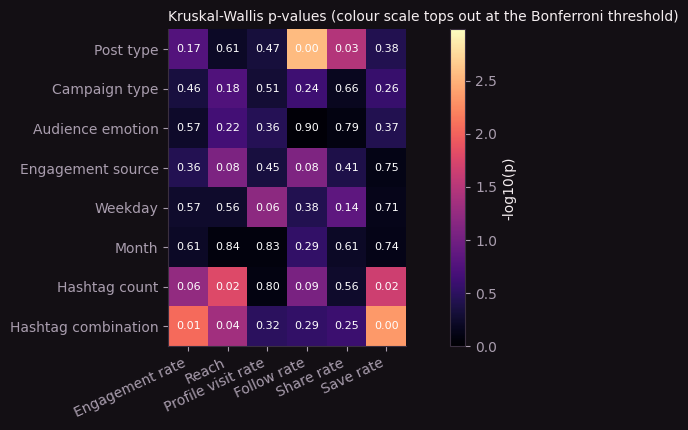

In [12]:
pivot = tests.pivot(index="dimension", columns="outcome", values="p_value").reindex(list(dimensions.keys()))[list(outcomes.keys())]
fig, ax = plt.subplots(figsize=(9, 4.4))
im = ax.imshow(-np.log10(pivot.values), cmap="magma", vmin=0, vmax=-np.log10(bonf))
ax.set_xticks(range(pivot.shape[1]), pivot.columns, rotation=25, ha="right")
ax.set_yticks(range(pivot.shape[0]), pivot.index)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        ax.text(j, i, f"{pivot.values[i, j]:.2f}", ha="center", va="center", color="white", fontsize=8)
ax.grid(False)
ax.set_title("Kruskal-Wallis p-values (colour scale tops out at the Bonferroni threshold)", fontsize=10, loc="left")
plt.colorbar(im, label="-log10(p)")
plt.tight_layout(); plt.show()

In [13]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, cross_val_score

feat = df[["post_type", "campaign_type", "audience_emotion", "engagement_source", "weekday", "month_label",
           "hashtag_count"] + [c for c in df.columns if c.startswith("tag_")]].copy()
for c in ["post_type", "campaign_type", "audience_emotion", "engagement_source", "month_label"]:
    feat[c] = feat[c].astype("category")
feat["weekday"] = feat["weekday"].cat.codes
for c in [c for c in feat.columns if c.startswith("tag_")]:
    feat[c] = feat[c].astype(int)

cv = KFold(n_splits=5, shuffle=True, random_state=42)
model_check = {}
for name, col in [("Engagement rate", "engagement_rate"), ("Reach", "reach"), ("Follow rate", "follow_rate")]:
    model = HistGradientBoostingRegressor(max_depth=3, max_iter=150, learning_rate=0.05,
                                          categorical_features="from_dtype", random_state=42)
    scores = cross_val_score(model, feat, df[col], cv=cv, scoring="r2")
    model_check[name] = {"r2_mean": round(float(scores.mean()), 4), "r2_std": round(float(scores.std()), 4)}
    print(f"{name:16s} cross-validated R2 = {scores.mean():+.4f}  (std {scores.std():.4f})")

Engagement rate  cross-validated R2 = -0.0004  (std 0.0002)


Reach            cross-validated R2 = -0.0001  (std 0.0002)


Follow rate      cross-validated R2 = -0.0001  (std 0.0002)


**Reading the result.** An R squared at or below zero means the model predicts no better than guessing the average. Every attribute the export contains, used together, tells us nothing about how a post will perform. The dashboard therefore reports each comparison with a confidence interval and a significance flag, and the Findings page says directly that format, weekday and hashtag choices are not measurable levers in this data.

One thing that is real: the metrics move together. Likes, comments, profile visits and follows all scale with reach. The next cell shows it.

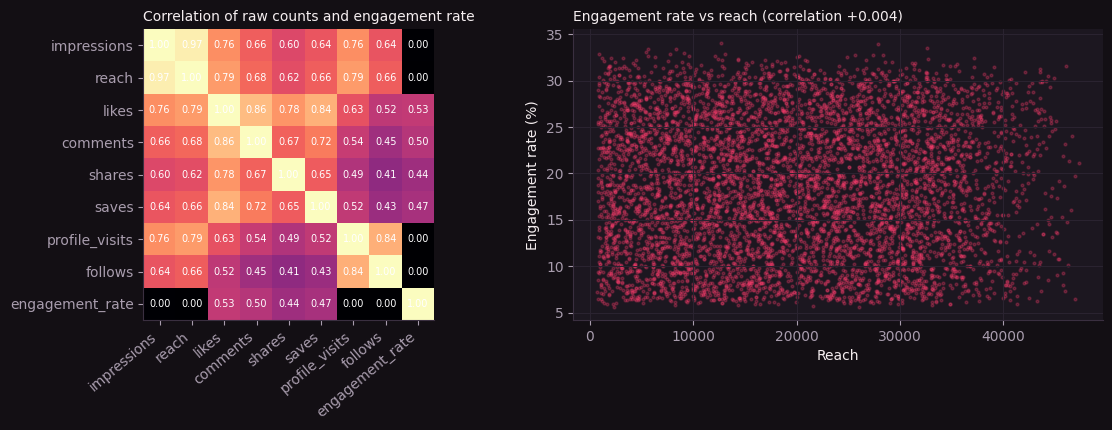

In [14]:
corr_cols = ["impressions", "reach", "likes", "comments", "shares", "saves", "profile_visits", "follows", "engagement_rate"]
corr = df[corr_cols].corr()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
im = axes[0].imshow(corr, cmap="magma", vmin=0, vmax=1)
axes[0].set_xticks(range(len(corr_cols)), corr_cols, rotation=40, ha="right"); axes[0].set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        axes[0].text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white")
axes[0].grid(False); axes[0].set_title("Correlation of raw counts and engagement rate", loc="left", fontsize=10)

axes[1].scatter(df.reach.sample(6000, random_state=1), df.engagement_rate.sample(6000, random_state=1), s=4, alpha=0.25, color=ROUGE)
axes[1].set_xlabel("Reach"); axes[1].set_ylabel("Engagement rate (%)")
axes[1].set_title(f"Engagement rate vs reach (correlation {df.reach.corr(df.engagement_rate):+.3f})", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## 7. Structure of the funnel, the interaction mix and the content calendar

These are descriptive facts about the account that hold regardless of the null results above.

In [15]:
tot = df[["impressions", "reach", "likes", "comments", "shares", "saves", "profile_visits", "follows", "total_interactions"]].sum()
funnel = pd.Series({
    "Reach as share of impressions": tot.reach / tot.impressions * 100,
    "Interactions as share of reach": tot.total_interactions / tot.reach * 100,
    "Profile visits as share of reach": tot.profile_visits / tot.reach * 100,
    "Follows as share of profile visits": tot.follows / tot.profile_visits * 100,
    "Follows per 1,000 reached": tot.follows / tot.reach * 1000,
    "Average views per reached account": tot.impressions / tot.reach,
}).round(2)
mix = (tot[["likes", "comments", "shares", "saves"]] / tot.total_interactions * 100).round(2)
print(funnel.to_string()); print(); print("Interaction mix (% of all interactions)"); print(mix.to_string())

Reach as share of impressions         77.38
Interactions as share of reach        18.55
Profile visits as share of reach       3.00
Follows as share of profile visits    29.92
Follows per 1,000 reached              8.98
Average views per reached account      1.29

Interaction mix (% of all interactions)
likes       80.65
comments    10.08
shares       4.43
saves        4.84


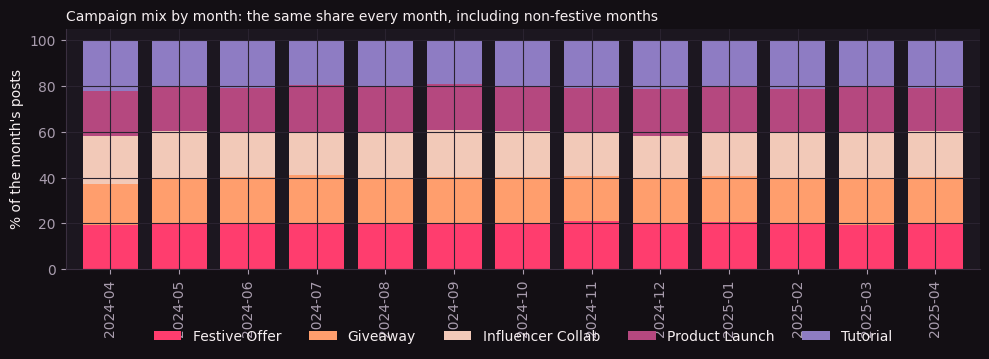

count    13.0
mean     19.9
std       0.5
min      19.2
25%      19.5
50%      19.9
75%      20.1
max      20.9
Name: Festive Offer, dtype: float64

In [16]:
cal = pd.crosstab(df.month_start.dt.strftime("%Y-%m"), df.campaign_type, normalize="index").mul(100).round(1)
ax = cal.plot(kind="bar", stacked=True, figsize=(10, 3.8), color=[ROUGE, APRICOT, NUDE, BERRY, ORCHID], width=0.8)
ax.set_ylabel("% of the month's posts"); ax.set_xlabel(""); ax.legend(ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2))
ax.set_title("Campaign mix by month: the same share every month, including non-festive months", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
cal.loc[:, "Festive Offer"].describe().round(1)

## 8. Export

Three files go to `dashboard/data/`. The clean CSV is reloaded and compared with the in-memory frame before the notebook finishes, so a silent export problem cannot slip through.

In [17]:
order_cols = [
    "post_id", "source_row", "post_date", "month_start", "month_label", "quarter", "week_start", "weekday", "weekday_num", "is_weekend",
    "month_days_covered", "is_partial_month",
    "post_type", "campaign_type", "audience_emotion", "engagement_source",
    "hashtags", "hashtag_combo", "hashtag_count",
    "tag_boldlooks", "tag_crueltyfree", "tag_makeupgoals", "tag_sugarcosmetics", "tag_veganbeauty",
    "impressions", "reach", "likes", "comments", "shares", "saves", "profile_visits", "follows",
    "total_interactions", "engagement_rate", "engagement_rate_impr", "reach_rate", "frequency",
    "like_rate", "comment_rate", "share_rate", "save_rate", "profile_visit_rate", "follow_rate",
    "follows_per_1k_reach", "high_intent_share", "reach_band", "hidden_gem", "post_label",
]
clean = df[order_cols].sort_values(["post_date", "post_id"]).reset_index(drop=True)
clean["weekday"] = clean["weekday"].astype(str)
clean["reach_band"] = clean["reach_band"].astype(str)
float_cols = clean.select_dtypes("float").columns
clean[float_cols] = clean[float_cols].round(4)   # keeps the file small without changing any reported figure
clean.to_csv(OUT_DIR / "sugar_ig_clean.csv", index=False)

summary = {
    "rows": int(len(clean)),
    "date_min": str(clean.post_date.min().date()), "date_max": str(clean.post_date.max().date()),
    "partial_months": [str(m.date()) for m in partial[partial].index],
    "engagement_rate_definition": "(likes + comments + shares + saves) / reach * 100",
    "hidden_gem_rule": {"engagement_rate_min": round(float(er_p75), 3), "reach_max": int(reach_p25)},
    "signal_tests": {"count": int(len(tests)), "bonferroni_threshold": round(bonf, 6),
                     "smallest_p": round(float(tests.p_value.min()), 4),
                     "below_raw_0_05": int((tests.p_value < 0.05).sum()),
                     "below_bonferroni": int((tests.p_value < bonf).sum()),
                     "largest_epsilon_sq": round(float(tests.epsilon_sq.max()), 6)},
    "model_check": model_check,
}
(OUT_DIR / "analysis_summary.json").write_text(json.dumps(summary, indent=2))
print("Saved", len(clean), "rows and", clean.shape[1], "columns")

Saved 50000 rows and 48 columns


In [18]:
# Data dictionary
dd = [
    ("post_id", "Generated ID (SC00001...) in raw-file order", "id"),
    ("source_row", "Row number in the raw Excel sheet", "id"),
    ("post_date", "Date the post was published", "date"),
    ("month_start / month_label", "First day of the month and its readable label", "date"),
    ("quarter / week_start", "Calendar quarter and the Monday of the post's week", "date"),
    ("weekday / weekday_num / is_weekend", "Day name (ordered Monday to Sunday), 1 to 7, and weekend flag", "date"),
    ("month_days_covered / is_partial_month", "Days with data in the month, and whether the export covers only part of it", "quality"),
    ("post_type", "Image, Reel, Story or Video", "category"),
    ("campaign_type", "Tutorial, Giveaway, Festive Offer, Product Launch or Influencer Collab", "category"),
    ("audience_emotion", "Dominant audience emotion tag", "category"),
    ("engagement_source", "Organic, Paid, Collab or Influencer", "category"),
    ("hashtags / hashtag_combo / hashtag_count", "Raw tag string, normalised sorted combination, and number of tags (1 to 3)", "category"),
    ("tag_*", "One True/False flag per hashtag", "flag"),
    ("impressions / reach", "Total views and unique accounts reached", "count"),
    ("likes / comments / shares / saves", "Interaction counts", "count"),
    ("profile_visits / follows", "Visits to the profile and new follows attributed to the post", "count"),
    ("total_interactions", "likes + comments + shares + saves", "derived"),
    ("engagement_rate", "total_interactions / reach x 100", "derived"),
    ("engagement_rate_impr", "total_interactions / impressions x 100", "derived"),
    ("reach_rate / frequency", "reach / impressions x 100, and impressions / reach", "derived"),
    ("like_rate / comment_rate / share_rate / save_rate", "Each interaction as a percent of reach", "derived"),
    ("profile_visit_rate", "profile_visits / reach x 100", "derived"),
    ("follow_rate", "follows / profile_visits x 100 (follows per profile visit)", "derived"),
    ("follows_per_1k_reach", "follows / reach x 1000", "derived"),
    ("high_intent_share", "(shares + saves) / total_interactions x 100", "derived"),
    ("reach_band", "Quintile of reach: Lowest 20%, Low, Middle, High, Highest 20%", "derived"),
    ("hidden_gem", "True if engagement rate is in the top 25% and reach in the bottom 25% (fixed thresholds)", "derived"),
    ("post_label", "Format | Campaign | Date, used in place of the missing caption", "derived"),
]
pd.DataFrame(dd, columns=["column", "description", "kind"]).to_csv(OUT_DIR / "data_dictionary.csv", index=False)

# Round trip check
back = pd.read_csv(OUT_DIR / "sugar_ig_clean.csv", parse_dates=["post_date", "month_start", "week_start"])
assert len(back) == len(raw) == 50000
assert back.post_id.is_unique
for c in ["impressions", "reach", "likes", "comments", "shares", "saves", "profile_visits", "follows"]:
    assert back[c].sum() == raw[c.replace("_", " ").title()].sum(), c
assert np.isclose(back.engagement_rate.mean(), clean.engagement_rate.mean())
print("Round trip passed. Files in output folder:", sorted(p.name for p in OUT_DIR.iterdir()))

Round trip passed. Files in output folder: ['analysis_summary.json', 'data_dictionary.csv', 'sugar_ig_clean.csv']
